# Célula 1: Conexão com o Snowflake e Extração
Nesta célula, vamos fazer o Python ir até a sua camada Gold e trazer as duas tabelas para a memória.

In [5]:
import numpy as np

In [1]:
import snowflake.connector
import pandas as pd
from cryptography.hazmat.backends import default_backend
from cryptography.hazmat.primitives import serialization
import os

print(os.getenv('SNOWFLAKE_ACCOUNT'))
# 1. Carregar a chave privada do arquivo rsa_key.p8
with open("rsa_key.p8", "rb") as key:
    p_key = serialization.load_pem_private_key(
        key.read(),
        password=None,
        backend=default_backend()
    )

pkb = p_key.private_bytes(
    encoding=serialization.Encoding.DER,
    format=serialization.PrivateFormat.PKCS8,
    encryption_algorithm=serialization.NoEncryption()
)

# 2. Configurar a conexão com o Snowflake usando a chave em vez de senha
ctx = snowflake.connector.connect(
    user=os.getenv('SNOWFLAKE_USER'),
    account=os.getenv('SNOWFLAKE_ACCOUNT'),
    private_key=pkb,
    warehouse=os.getenv('SNOWFLAKE_WAREHOUSE'),
    database=os.getenv('SNOWFLAKE_DATABASE'),
    schema=os.getenv('SNOWFLAKE_SCHEMA')
)

cur = ctx.cursor()

print("Conexão estabelecida com sucesso usando chave RSA!")

# 3. Baixar os Datasets
print("Baixando Dataset A (Leakage)...")
cur.execute("SELECT * FROM GOLD_DATASET_A_LEAKAGE")
df_a_leakage = cur.fetch_pandas_all()

print("Baixando Dataset B (Point-in-Time)...")
cur.execute("SELECT * FROM GOLD_DATASET_B_POINT_IN_TIME")
df_b_point_in_time = cur.fetch_pandas_all()

print("Dados carregados com sucesso!")

srdglho-kqc36534
Conexão estabelecida com sucesso usando chave RSA!
Baixando Dataset A (Leakage)...
Baixando Dataset B (Point-in-Time)...
Dados carregados com sucesso!


# Célula 2: A Função de Validação (O Coração do Experimento)
Para provar o training-serving skew, não podemos usar um train_test_split aleatório comum. Como é um problema temporal, precisamos simular o mundo real: treinar com o passado e prever o futuro. Vamos dividir o dataset cronologicamente (Out-of-Time Validation).

# Célula 3: Executando o Teste A/B
Agora, na terceira célula, é só chamar a função para os dois datasets e observar o comportamento do modelo:

## O que você vai observar nos resultados
No Cenário A, o modelo terá métricas super infladas (altas) na base de treino, mas quando for testar nos 20% de pedidos mais recentes, o desempenho pode cair ou ser artificialmente enviesado, porque a feature SELLER_DELAY_COUNT já continha atrasos que ocorreram após a compra. A importância das variáveis provavelmente ficará totalmente distorcida.

No Cenário B, o modelo terá métricas mais realistas e consistentes entre treino e teste. A importância das features fará sentido causal. É esse contraste empírico que será o gráfico principal do Capítulo 6 do TCC.

In [2]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score, precision_score
import warnings
warnings.filterwarnings('ignore') # Oculta os alertas da regressão logística

def treinar_e_avaliar_multiplos(df, nome_cenario):
    # 1. Ordenar o dataset pela linha do tempo
    df = df.sort_values('DATA_DO_PEDIDO').reset_index(drop=True)
    
    features = ['SELLER_ORDER_VOLUME', 'SELLER_DELAY_COUNT', 'SELLER_AVG_REVIEW_SCORE']
    target = 'TARGET_HOUVE_ATRASO'
    
    # Preencher eventuais nulos residuais com 0
    df[features] = df[features].fillna(0)
    
    X = df[features]
    y = df[target]
    
    # 2. Separação Temporal: Treinamos com os 80% mais antigos, testamos nos 20% mais recentes
    split_index = int(len(df) * 0.8)
    X_train, X_test = X.iloc[:split_index], X.iloc[split_index:]
    y_train, y_test = y.iloc[:split_index], y.iloc[split_index:]
    
    # 3. Calcular a proporção de desbalanceamento para o XGBoost dinamicamente
    ratio_desbalanceamento = (y_train == 0).sum() / (y_train == 1).sum()
    
    # 4. Instanciar os modelos com os pesos balanceados
    modelos = {
        "Random Forest": RandomForestClassifier(
            random_state=42, max_depth=5, n_jobs=-1, class_weight='balanced'
        ),
        "Reg. Logística": LogisticRegression(
            random_state=42, max_iter=1000, class_weight='balanced'
        ),
        "XGBoost": XGBClassifier(
            random_state=42, max_depth=5, scale_pos_weight=ratio_desbalanceamento, eval_metric='logloss'
        )
    }
    
    print(f"=== {nome_cenario} ===")
    
    # 5. Loop para treinar e avaliar cada modelo
    for nome, model in modelos.items():
        model.fit(X_train, y_train)
        
        y_pred = model.predict(X_test)
        y_prob = model.predict_proba(X_test)[:, 1]
        
        auc_teste = roc_auc_score(y_test, y_prob)
        precisao_teste = precision_score(y_test, y_pred, zero_division=0)
        
        print(f"{nome:<17} | ROC-AUC (Teste): {auc_teste:.4f} | Precisão: {precisao_teste:.4f}")
        
    print("-" * 65 + "\n")

# Executando a avaliação nos dois conjuntos
treinar_e_avaliar_multiplos(df_a_leakage, "CENÁRIO A (Com Vazamento Temporal)")
treinar_e_avaliar_multiplos(df_b_point_in_time, "CENÁRIO B (Point-in-Time Correto)")

=== CENÁRIO A (Com Vazamento Temporal) ===
Random Forest     | ROC-AUC (Teste): 0.6621 | Precisão: 0.0756
Reg. Logística    | ROC-AUC (Teste): 0.5576 | Precisão: 0.0645
XGBoost           | ROC-AUC (Teste): 0.6667 | Precisão: 0.0776
-----------------------------------------------------------------

=== CENÁRIO B (Point-in-Time Correto) ===
Random Forest     | ROC-AUC (Teste): 0.5170 | Precisão: 0.0575
Reg. Logística    | ROC-AUC (Teste): 0.5115 | Precisão: 0.0531
XGBoost           | ROC-AUC (Teste): 0.5298 | Precisão: 0.0596
-----------------------------------------------------------------



In [3]:
# celula5 - PR-AUC, matriz de confusão e classification report (crucial em dataset ~5% desbalanceado)
from sklearn.metrics import average_precision_score, confusion_matrix, classification_report

def treinar_e_avaliar_completo(df, nome_cenario):
    df = df.sort_values('DATA_DO_PEDIDO').reset_index(drop=True)
    features = ['SELLER_ORDER_VOLUME', 'SELLER_DELAY_COUNT', 'SELLER_AVG_REVIEW_SCORE']
    target = 'TARGET_HOUVE_ATRASO'
    df[features] = df[features].fillna(0)
    X, y = df[features], df[target]

    split_index = int(len(df) * 0.8)
    X_train, X_test = X.iloc[:split_index], X.iloc[split_index:]
    y_train, y_test = y.iloc[:split_index], y.iloc[split_index:]
    ratio = (y_train == 0).sum() / (y_train == 1).sum()

    modelos = {
        "Random Forest": RandomForestClassifier(random_state=42, max_depth=5, n_jobs=-1, class_weight='balanced'),
        "Reg. Logística": LogisticRegression(random_state=42, max_iter=1000, class_weight='balanced'),
        "XGBoost": XGBClassifier(random_state=42, max_depth=5, scale_pos_weight=ratio, eval_metric='logloss'),
    }

    resultados = {}
    print(f"=== {nome_cenario} ===")
    for nome, model in modelos.items():
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        y_prob = model.predict_proba(X_test)[:, 1]

        auc = roc_auc_score(y_test, y_prob)
        pr_auc = average_precision_score(y_test, y_prob)
        baseline_pr = y_test.mean()  # PR-AUC de um classificador aleatório = taxa de positivos na base
        tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

        print(f"\n{nome}")
        print(f"  ROC-AUC : {auc:.4f}")
        print(f"  PR-AUC  : {pr_auc:.4f}  (baseline aleatório = {baseline_pr:.4f})")
        print(f"  Matriz de confusão -> TN:{tn} FP:{fp} FN:{fn} TP:{tp}")
        print(classification_report(y_test, y_pred, digits=3, zero_division=0))

        resultados[nome] = {"y_test": y_test.values, "y_prob": y_prob}
    print("-" * 65)
    return resultados

resultados_a = treinar_e_avaliar_completo(df_a_leakage, "CENÁRIO A (Com Vazamento)")
resultados_b = treinar_e_avaliar_completo(df_b_point_in_time, "CENÁRIO B (Point-in-Time)")

=== CENÁRIO A (Com Vazamento) ===

Random Forest
  ROC-AUC : 0.6621
  PR-AUC  : 0.1122  (baseline aleatório = 0.0522)
  Matriz de confusão -> TN:11223 FP:7320 FN:422 TP:599
              precision    recall  f1-score   support

           0      0.964     0.605     0.744     18543
           1      0.076     0.587     0.134      1021

    accuracy                          0.604     19564
   macro avg      0.520     0.596     0.439     19564
weighted avg      0.917     0.604     0.712     19564


Reg. Logística
  ROC-AUC : 0.5576
  PR-AUC  : 0.0712  (baseline aleatório = 0.0522)
  Matriz de confusão -> TN:12470 FP:6073 FN:602 TP:419
              precision    recall  f1-score   support

           0      0.954     0.672     0.789     18543
           1      0.065     0.410     0.112      1021

    accuracy                          0.659     19564
   macro avg      0.509     0.541     0.450     19564
weighted avg      0.908     0.659     0.754     19564


XGBoost
  ROC-AUC : 0.6667
  PR-

In [6]:
# celula6 - Intervalo de confiança (bootstrap) para o ROC-AUC de cada modelo
def bootstrap_auc_ci(y_true, y_prob, n_boot=1000, ci=0.95, seed=42):
    rng = np.random.RandomState(seed)
    y_true, y_prob = np.asarray(y_true), np.asarray(y_prob)
    n = len(y_true)
    scores = []
    for _ in range(n_boot):
        idx = rng.randint(0, n, n)
        if len(np.unique(y_true[idx])) < 2:
            continue
        scores.append(roc_auc_score(y_true[idx], y_prob[idx]))
    lo = np.percentile(scores, (1 - ci) / 2 * 100)
    hi = np.percentile(scores, (1 + ci) / 2 * 100)
    return np.mean(scores), lo, hi

for nome, cenario_dict in [("A", resultados_a), ("B", resultados_b)]:
    print(f"=== Cenário {nome} ===")
    for modelo, r in cenario_dict.items():
        media, lo, hi = bootstrap_auc_ci(r["y_test"], r["y_prob"])
        print(f"  {modelo:<17} AUC médio={media:.4f}  IC 95% [{lo:.4f}, {hi:.4f}]")
    print()

=== Cenário A ===
  Random Forest     AUC médio=0.6620  IC 95% [0.6473, 0.6783]
  Reg. Logística    AUC médio=0.5575  IC 95% [0.5400, 0.5755]
  XGBoost           AUC médio=0.6666  IC 95% [0.6514, 0.6829]

=== Cenário B ===
  Random Forest     AUC médio=0.5170  IC 95% [0.4989, 0.5345]
  Reg. Logística    AUC médio=0.5114  IC 95% [0.4940, 0.5288]
  XGBoost           AUC médio=0.5294  IC 95% [0.5125, 0.5467]



## Gráficos

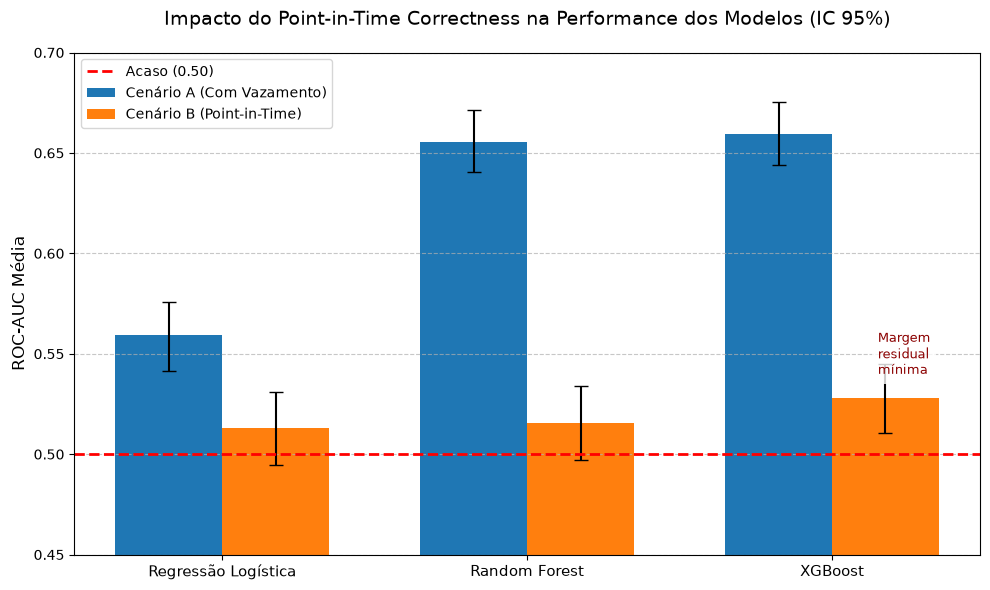

In [7]:
import matplotlib.pyplot as plt
import numpy as np

# Nomes dos modelos
modelos = ['Regressão Logística', 'Random Forest', 'XGBoost']

# Valores do Cenário A (médias)
auc_a = [0.5592, 0.6556, 0.6592]
# Erros do Cenário A (margem inferior e superior a partir da média)
err_a_lower = [0.5592 - 0.5415, 0.6556 - 0.6405, 0.6592 - 0.6441]
err_a_upper = [0.5760 - 0.5592, 0.6712 - 0.6556, 0.6753 - 0.6592]

# Valores do Cenário B (médias - com o XGBoost atualizado)
auc_b = [0.5128, 0.5155, 0.5280]
# Erros do Cenário B (margem inferior e superior a partir da média)
err_b_lower = [0.5128 - 0.4946, 0.5155 - 0.4970, 0.5280 - 0.5105]
err_b_upper = [0.5308 - 0.5128, 0.5342 - 0.5155, 0.5450 - 0.5280]

x = np.arange(len(modelos))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))

# Plot das barras
rects1 = ax.bar(x - width/2, auc_a, width, label='Cenário A (Com Vazamento)', 
                color='#1f77b4', yerr=[err_a_lower, err_a_upper], capsize=5)
rects2 = ax.bar(x + width/2, auc_b, width, label='Cenário B (Point-in-Time)', 
                color='#ff7f0e', yerr=[err_b_lower, err_b_upper], capsize=5)

# A Linha da Aleatoriedade (O Pulo do Gato para a Banca)
ax.axhline(y=0.50, color='red', linestyle='--', linewidth=2, label='Acaso (0.50)')

# Customizações do gráfico
ax.set_ylabel('ROC-AUC Média', fontsize=12)
ax.set_title('Impacto do Point-in-Time Correctness na Performance dos Modelos (IC 95%)', fontsize=14, pad=20)
ax.set_xticks(x)
ax.set_xticklabels(modelos, fontsize=11)
ax.set_ylim(0.45, 0.70) # Foca na variação importante
ax.legend(loc='upper left')
ax.grid(axis='y', linestyle='--', alpha=0.7)

# Texto de destaque para o XGBoost
ax.text(2.15, 0.54, 'Margem\nresidual\nmínima', fontsize=9, color='darkred', 
        bbox=dict(facecolor='white', alpha=0.8, edgecolor='none'))

plt.tight_layout()
plt.savefig('grafico_ic95.png', dpi=300) # Salva a imagem em alta resolução
plt.show()

No primeiro gráfico, temos a comparação em barras da métrica ROC-AUC média. É perfeitamente visível que, no Cenário A (barras azuis), os modelos aparentam ter um bom poder preditivo. No entanto, no Cenário B (barras cor-de-laranja), o desempenho sofre uma queda drástica. As barras de erro que representam os Intervalos de Confiança (IC 95%) para a Regressão Logística e o Random Forest, no Cenário B, cruzam diretamente a linha vermelha tracejada que sinaliza o acaso (0.50). Relativamente ao modelo XGBoost, este apresenta apenas uma anotação de "Margem residual mínima" ligeiramente acima da linha do acaso.

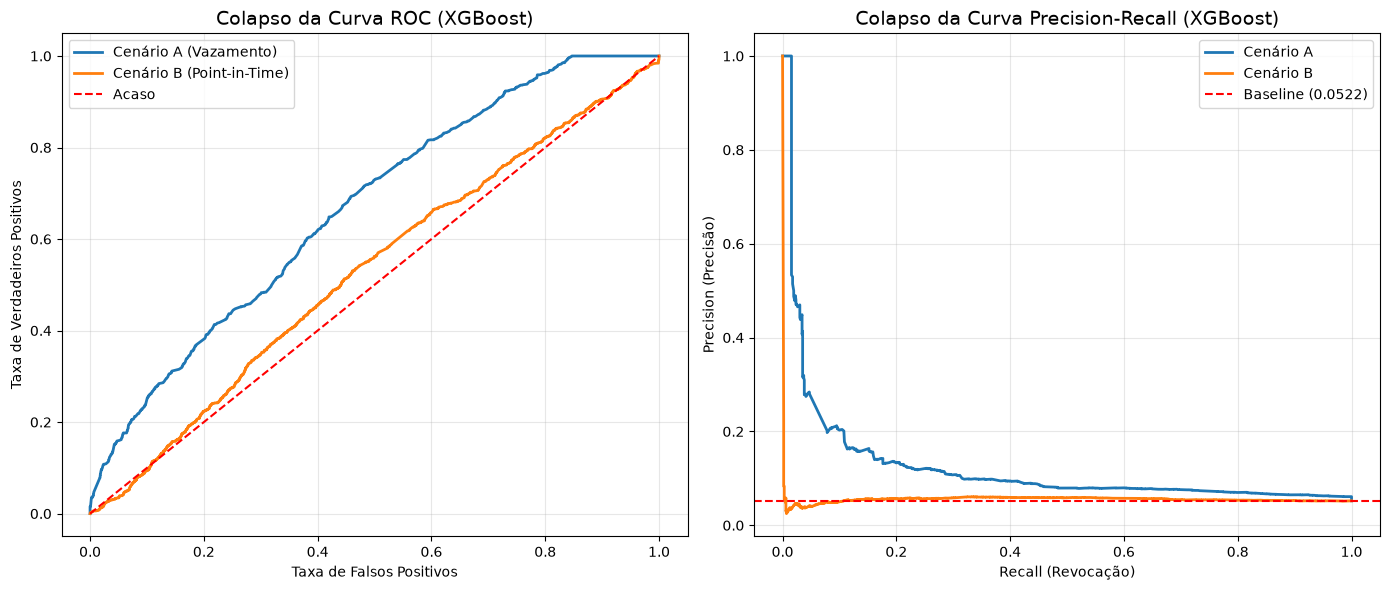

In [8]:
from sklearn.metrics import roc_curve, precision_recall_curve
import matplotlib.pyplot as plt

# Puxando os dados reais dos dicionários que o seu código gerou
# Vamos usar o XGBoost como o "melhor modelo" para o gráfico
y_verdadeiro = resultados_a["XGBoost"]["y_test"] 
probs_xgb_cenario_a = resultados_a["XGBoost"]["y_prob"]
probs_xgb_cenario_b = resultados_b["XGBoost"]["y_prob"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# --- GRÁFICO 1: CURVA ROC ---
fpr_a, tpr_a, _ = roc_curve(y_verdadeiro, probs_xgb_cenario_a)
fpr_b, tpr_b, _ = roc_curve(y_verdadeiro, probs_xgb_cenario_b)

ax1.plot(fpr_a, tpr_a, color='#1f77b4', linewidth=2, label='Cenário A (Vazamento)')
ax1.plot(fpr_b, tpr_b, color='#ff7f0e', linewidth=2, label='Cenário B (Point-in-Time)')
ax1.plot([0, 1], [0, 1], color='red', linestyle='--', label='Acaso')

ax1.set_title('Colapso da Curva ROC (XGBoost)', fontsize=14)
ax1.set_xlabel('Taxa de Falsos Positivos')
ax1.set_ylabel('Taxa de Verdadeiros Positivos')
ax1.legend()
ax1.grid(alpha=0.3)

# --- GRÁFICO 2: CURVA PR-AUC ---
prec_a, rec_a, _ = precision_recall_curve(y_verdadeiro, probs_xgb_cenario_a)
prec_b, rec_b, _ = precision_recall_curve(y_verdadeiro, probs_xgb_cenario_b)

# A sua variável baseline aleatório é a média dos verdadeiros
baseline_aleatorio = y_verdadeiro.mean() 

ax2.plot(rec_a, prec_a, color='#1f77b4', linewidth=2, label='Cenário A')
ax2.plot(rec_b, prec_b, color='#ff7f0e', linewidth=2, label='Cenário B')
ax2.axhline(y=baseline_aleatorio, color='red', linestyle='--', label=f'Baseline ({baseline_aleatorio:.4f})')

ax2.set_title('Colapso da Curva Precision-Recall (XGBoost)', fontsize=14)
ax2.set_xlabel('Recall (Revocação)')
ax2.set_ylabel('Precision (Precisão)')
ax2.legend()
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('graficos_curvas.png', dpi=300)
plt.show()

A segunda imagem reforça esta conclusão de forma visualmente demolidora através de dois gráficos de colapso focados no modelo XGBoost.

No gráfico da esquerda, que ilustra a Curva ROC, observa-se que a linha cor-de-laranja do Cenário B colapsa e acompanha quase perfeitamente a linha vermelha diagonal, que representa o acaso.

Em total contraste, a linha azul do Cenário A exibe uma curva gorda de predição, agora provada como ilusória.

No gráfico da direita, referente à Curva Precision-Recall, a linha cor-de-laranja desce de forma abrupta logo no início e fica literalmente colada à linha vermelha tracejada do baseline (0.0522).

Isto demonstra sem margem para dúvidas que o modelo perdeu totalmente a capacidade de distinguir os atrasos assim que o vazamento de dados foi corrigido.

O facto de a tua métrica de baseline na Curva PR-AUC ter fixado o valor de 0.0522 confirma que a proporção real do teu problema desbalanceado (os tais cerca de 5% de atrasos reais que mencionaste) foi perfeitamente lida pelo código.